# TASK 02_ Adaptive Thresholding

In [ ]:
# Cell 1 — imports and settings
from pathlib import Path
import time
import csv
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = Path("data") / "task02_uneven.jpg"
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
TARGET_WIDTH = 800

#print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


In [3]:
# Cell 2 — load, resize, grayscale
image = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR)
if image is None:
    raise FileNotFoundError(f"Could not read the image: {IMAGE_PATH}")

h, w = image.shape[:2]
new_h = round(h * TARGET_WIDTH / w)
resized = cv2.resize(image, (TARGET_WIDTH, new_h), interpolation=cv2.INTER_AREA)
gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

print(f"Original: {w} x {h}  ->  resized: {TARGET_WIDTH} x {new_h}")
print(f"Gray: shape {gray.shape}, mean {gray.mean():.1f}, min {gray.min()}, "
      f"max {gray.max()}, std {gray.std():.1f}")
cv2.imwrite(str(RESULTS_DIR / "task02_gray.png"), gray)

Original: 3000 x 4000  ->  resized: 800 x 1067
Gray: shape (1067, 800), mean 112.5, min 1, max 255, std 43.6


True

Mean brightness in a 3x3 grid:
 [[ 65.  92. 127.]
 [ 81. 109. 166.]
 [ 84. 122. 166.]]
Darkest / brightest region: 65 / 166  (ratio 2.55x)


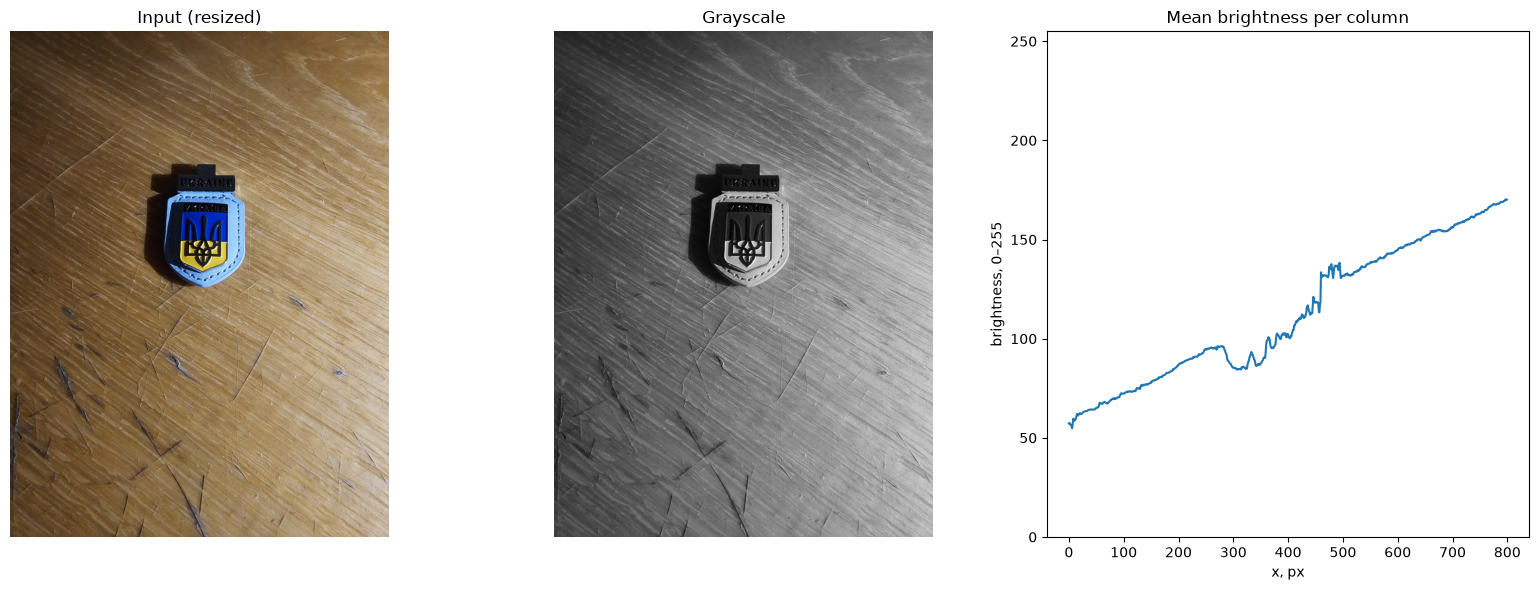

In [5]:
# Cell 3 — illumination profile: is the lighting really uneven?

# Get the height (H) and width (W) of the grayscale image
H, W = gray.shape

# Create an empty 3x3 array for the average brightness values
grid = np.zeros((3, 3))

# Divide the image into 3 rows and 3 columns
for i in range(3):
    for j in range(3):

        # Calculate the boundaries of the current region
        y_start = i * H // 3
        y_end = (i + 1) * H // 3

        x_start = j * W // 3
        x_end = (j + 1) * W // 3

        # Extract the current region from the grayscale image
        region = gray[y_start:y_end, x_start:x_end]

        # Calculate the average brightness of this region
        grid[i, j] = region.mean()

print("Mean brightness in a 3x3 grid:\n", grid.round(0))

print(f"Darkest / brightest region: {grid.min():.0f} / {grid.max():.0f}  "
      f"(ratio {grid.max() / grid.min():.2f}x)")


# Column profile: average brightness of each column, left to right
col_profile = gray.mean(axis=0)


# Create a figure with three plots
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# Plot 1: resized input image
axes[0].imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
axes[0].set_title("Input (resized)")

# Plot 2: grayscale image
axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale")

# Plot 3: average brightness of each image column
axes[2].plot(col_profile)
axes[2].set_title("Mean brightness per column")
axes[2].set_xlabel("x, px")
axes[2].set_ylabel("brightness, 0–255")
axes[2].set_ylim(0, 255)

# Remove axes from the two image plots
for ax in axes[:2]:
    ax.axis("off")

# Adjust spacing between the plots
plt.tight_layout()

# Save the figure
plt.savefig(RESULTS_DIR / "task02_step1_illumination.png", dpi=150)

# Display the figure
plt.show()

That makes the code much easier to connect to the purpose of this cell: checking whether illumination varies across the image before choosing an appropriate thresholding method.

--- Global threshold, T = 127 ---
T =  80 | white total  73.9% | left third  40.9% | right third  99.8%
T = 127 | white total  38.1% | left third   0.9% | right third  81.2%
T = 170 | white total  11.0% | left third   0.0% | right third  28.5%


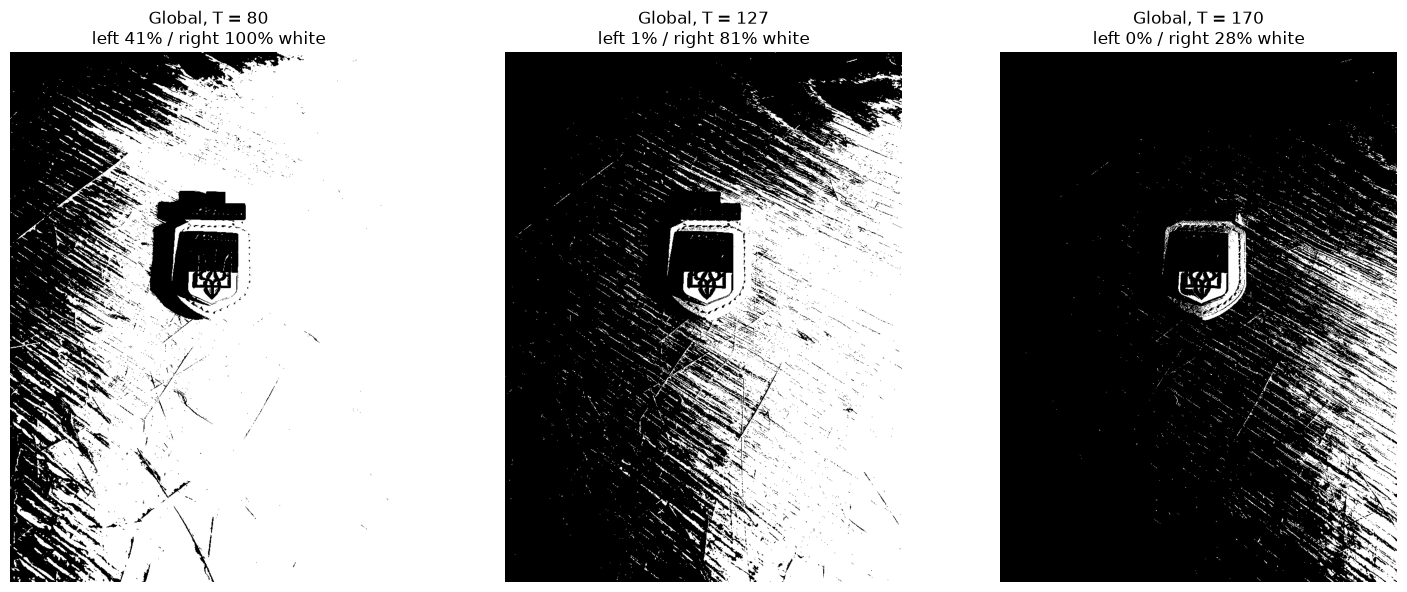

In [14]:
# Cell 4 — global threshold: required result + threshold experiment
GLOBAL_T = 127                      # the main (required) result
T_VALUES = [80, 127, 170]           # experiment: low / middle / high

t_used, binary_global = cv2.threshold(gray, GLOBAL_T, 255, cv2.THRESH_BINARY)
cv2.imwrite(str(RESULTS_DIR / "task02_1_global.png"), binary_global)

def white_pct(b):
    """Share of white pixels, %."""
    return 100 * cv2.countNonZero(b) / b.size

def left_right_white(b):
    """White % in the left and right thirds: shows the lighting bias."""
    W = b.shape[1]
    return white_pct(b[:, :W // 3]), white_pct(b[:, 2 * W // 3:])

print(f"--- Global threshold, T = {t_used:.0f} ---")
fig, axes = plt.subplots(1, (len(T_VALUES)), figsize=(15, 6))
for ax, T in zip(axes, T_VALUES):
    _, b = cv2.threshold(gray, T, 255, cv2.THRESH_BINARY)
    left, right = left_right_white(b)
    print(f"T = {T:3d} | white total {white_pct(b):5.1f}% | "
          f"left third {left:5.1f}% | right third {right:5.1f}%")
    ax.imshow(b, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Global, T = {T}\nleft {left:.0f}% / right {right:.0f}% white")
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task02_step2_global_T.png", dpi=150)
plt.show()


--- Global threshold (main result T = 127) ---
T =  80 | white total  73.9% | left third  40.9% | right third  99.8% | profile crosses T at x = 164
T = 127 | white total  38.1% | left third   0.9% | right third  81.2% | profile crosses T at x = 460
T = 170 | white total  11.0% | left third   0.0% | right third  28.5% | profile crosses T at x = 797


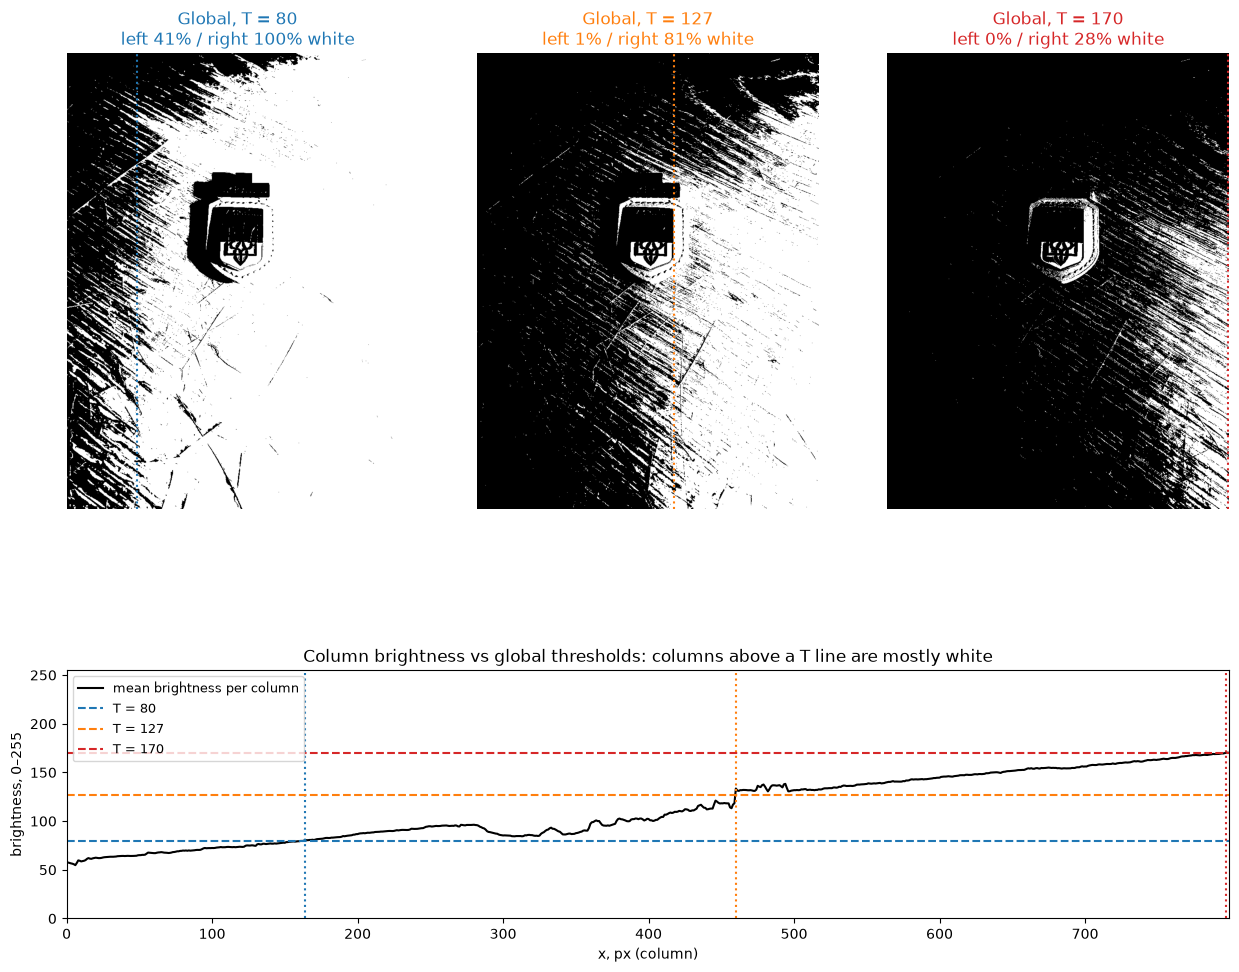

In [16]:
# Cell 4 — global threshold: required result + threshold experiment + profile
GLOBAL_T = 127                                   # the main (required) result
T_VALUES = [80, 127, 170]                        # experiment: low / middle / high
T_COLORS = ["tab:blue", "tab:orange", "tab:red"]

t_used, binary_global = cv2.threshold(gray, GLOBAL_T, 255, cv2.THRESH_BINARY)
_ = cv2.imwrite(str(RESULTS_DIR / "task02_1_global.png"), binary_global)

def white_pct(b):
    """Share of white pixels, %."""
    return 100 * cv2.countNonZero(b) / b.size

def left_right_white(b):
    """White % in the left and right thirds: shows the lighting bias."""
    W = b.shape[1]
    return white_pct(b[:, :W // 3]), white_pct(b[:, 2 * W // 3:])

col_profile = gray.mean(axis=0)                  # mean brightness of each column
x = np.arange(len(col_profile))

fig = plt.figure(figsize=(15, 12))
gs = fig.add_gridspec(2, 3, height_ratios=[3, 1.3], hspace=0.25)
top_axes = [fig.add_subplot(gs[0, i]) for i in range(3)]
ax_prof = fig.add_subplot(gs[1, :])              # second row, full width

print(f"--- Global threshold (main result T = {t_used:.0f}) ---")
ax_prof.plot(x, col_profile, color="black", linewidth=1.5, label="mean brightness per column")

for ax, T, c in zip(top_axes, T_VALUES, T_COLORS):
    _, b = cv2.threshold(gray, T, 255, cv2.THRESH_BINARY)
    left, right = left_right_white(b)

    # first column whose mean brightness exceeds T = approximate black/white boundary
    above = np.where(col_profile > T)[0]
    cross = int(above[0]) if above.size else None

    print(f"T = {T:3d} | white total {white_pct(b):5.1f}% | left third {left:5.1f}% | "
          f"right third {right:5.1f}% | profile crosses T at x = {cross}")

    ax.imshow(b, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Global, T = {T}\nleft {left:.0f}% / right {right:.0f}% white", color=c)
    if cross is not None:
        ax.axvline(cross, color=c, linestyle=":", linewidth=1.5)   # same x on the image
    ax.axis("off")

    ax_prof.axhline(T, color=c, linestyle="--", label=f"T = {T}")
    if cross is not None:
        ax_prof.axvline(cross, color=c, linestyle=":")

ax_prof.set_xlim(0, len(col_profile) - 1)
ax_prof.set_ylim(0, 255)
ax_prof.set_xlabel("x, px (column)")
ax_prof.set_ylabel("brightness, 0–255")
ax_prof.set_title("Column brightness vs global thresholds: columns above a T line are mostly white")
ax_prof.legend(loc="upper left", fontsize=9)

plt.savefig(RESULTS_DIR / "task02_step2_global_T.png", dpi=150, bbox_inches="tight")
plt.show()

# step 5

--- Adaptive MEAN: blockSize x C ---
block  11 | C  2 | white  56.7% | left  53.9% | right  59.9% | fragments  395
block  11 | C  5 | white  73.3% | left  75.6% | right  73.4% | fragments  792
block  11 | C 10 | white  87.4% | left  92.2% | right  85.5% | fragments  363
block  51 | C  2 | white  52.6% | left  49.9% | right  56.9% | fragments  198
block  51 | C  5 | white  65.8% | left  66.9% | right  68.4% | fragments  459
block  51 | C 10 | white  81.9% | left  87.4% | right  82.1% | fragments  426
block 151 | C  2 | white  53.4% | left  51.1% | right  56.7% | fragments  194
block 151 | C  5 | white  64.7% | left  65.4% | right  66.9% | fragments  336
block 151 | C 10 | white  81.0% | left  86.9% | right  81.4% | fragments  340


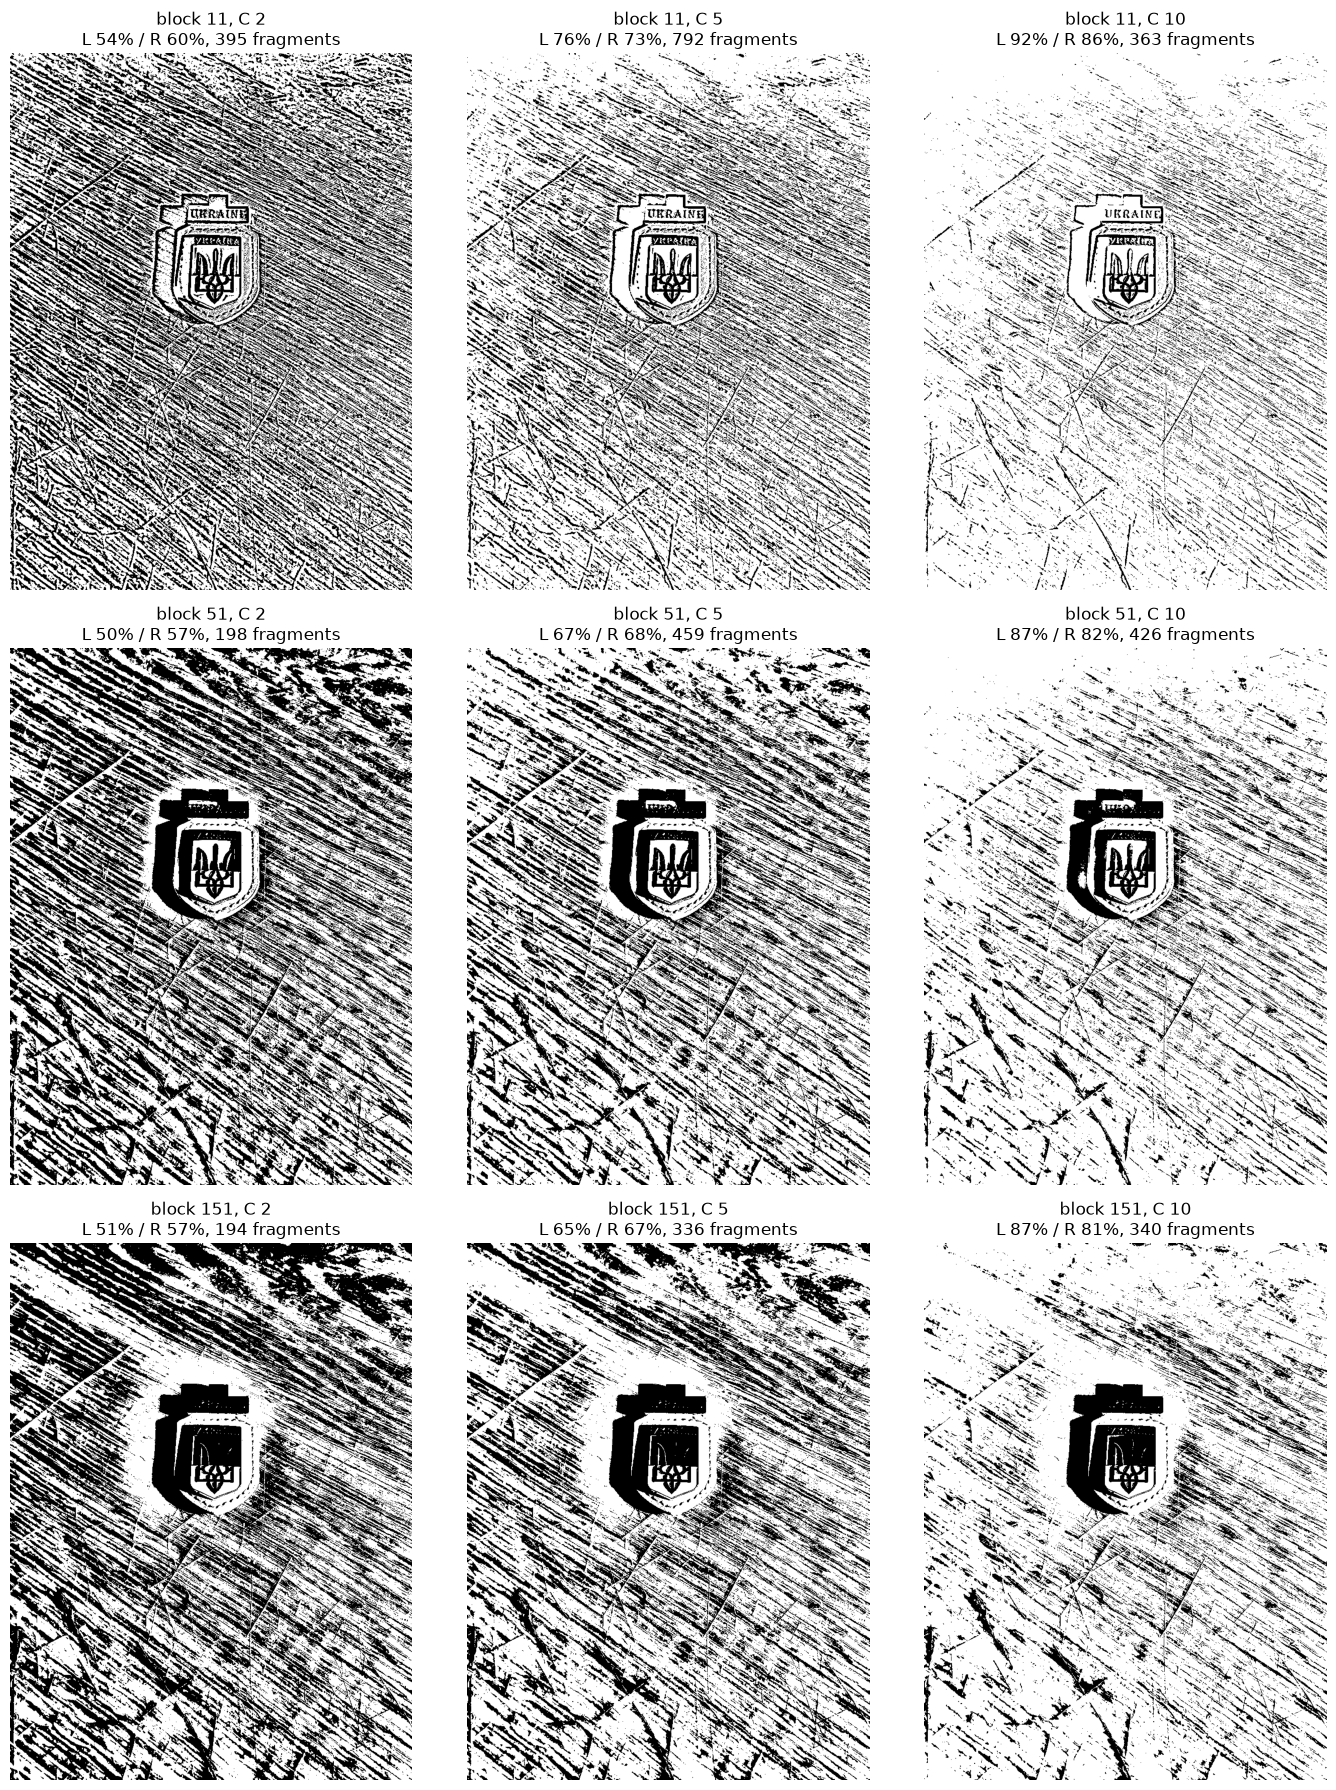

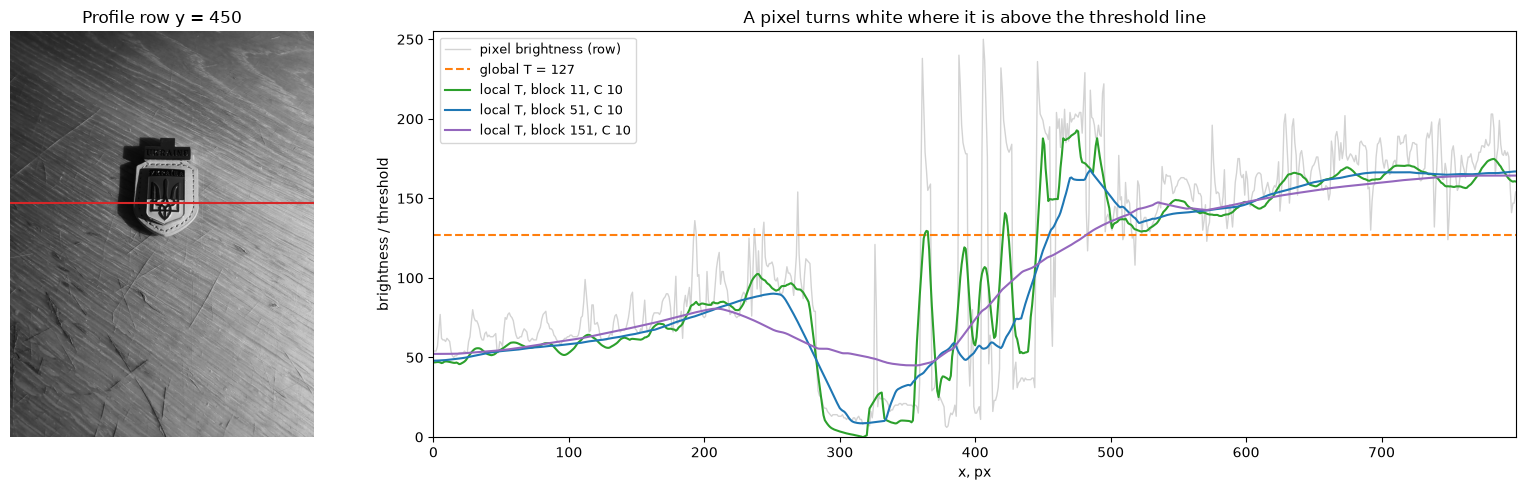

In [ ]:
# Cell 5 — adaptive MEAN: main result + blockSize × C experiment + "why" profile
AM_BLOCK, AM_C = 51, 10                      # main result (justify in the report)
BLOCKS = [11, 51, 151]                       # experiment: small / medium / large neighbourhood
CS = [2, 5, 10]                              # experiment: weak / medium / strong offset
ROW_Y = 450                                  # a row passing through the badge (for the profile)

binary_amean = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                     cv2.THRESH_BINARY, AM_BLOCK, AM_C)
_ = cv2.imwrite(str(RESULTS_DIR / "task02_2_adaptive_mean.png"), binary_amean)

def n_fragments(b, min_area=50):
    """Number of black regions of at least min_area pixels (wood grain, details, objects)."""
    n, _, stats, _ = cv2.connectedComponentsWithStats(255 - b, connectivity=8)
    return int((stats[1:, cv2.CC_STAT_AREA] >= min_area).sum())

# --- 3 x 3 experiment grid ---
rows_out = []
fig, axes = plt.subplots(len(BLOCKS), len(CS), figsize=(14, 18))
print("--- Adaptive MEAN: blockSize x C ---")
for i, bs in enumerate(BLOCKS):
    for j, C in enumerate(CS):
        b = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                  cv2.THRESH_BINARY, bs, C)
        left, right = left_right_white(b)
        frag = n_fragments(b)
        rows_out.append(["mean", bs, C, round(white_pct(b), 1), round(left, 1),
                         round(right, 1), frag])
        print(f"block {bs:3d} | C {C:2d} | white {white_pct(b):5.1f}% | "
              f"left {left:5.1f}% | right {right:5.1f}% | fragments {frag:4d}")
        axes[i, j].imshow(b, cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(f"block {bs}, C {C}\nL {left:.0f}% / R {right:.0f}%, {frag} fragments")
        axes[i, j].axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task02_step3_adaptive_mean_grid.png", dpi=120, bbox_inches="tight")
plt.show()

# G lobal T vs local thresholds along one row ---
fig, (ax_img, ax_row) = plt.subplots(1, 2, figsize=(16, 5),
                                     gridspec_kw={"width_ratios": [1, 2.5]})
ax_img.imshow(gray, cmap="gray", vmin=0, vmax=255)
ax_img.axhline(ROW_Y, color="tab:red", linewidth=1.5)
ax_img.set_title(f"Profile row y = {ROW_Y}")
ax_img.axis("off")

ax_row.plot(gray[ROW_Y, :], color="lightgray", linewidth=1, label="pixel brightness (row)")
ax_row.axhline(GLOBAL_T, color="tab:orange", linestyle="--", label=f"global T = {GLOBAL_T}")
for bs, c in zip(BLOCKS, ["tab:green", "tab:blue", "tab:purple"]):
    local_T = cv2.blur(gray.astype(np.float32), (bs, bs))[ROW_Y, :] - AM_C
    ax_row.plot(local_T, color=c, linewidth=1.5, label=f"local T, block {bs}, C {AM_C}")
ax_row.set_xlim(0, gray.shape[1] - 1)
ax_row.set_ylim(0, 255)
ax_row.set_xlabel("x, px")
ax_row.set_ylabel("brightness / threshold")
ax_row.set_title("A pixel turns white where it is above the threshold line")
ax_row.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task02_step3_local_threshold_profile.png", dpi=150, bbox_inches="tight")
plt.show()

# Step 4 — Adaptive Gaussian (image 3 of 5)

--- MEAN vs GAUSSIAN, C = 10 ---
block  11 | MEAN white  87.4%, fragments  363 | GAUSS white  90.5% (L 95.1 / R 88.3), fragments  181 | pixels differing  4.6%
block  51 | MEAN white  81.9%, fragments  426 | GAUSS white  84.1% (L 89.0 / R 83.4), fragments  428 | pixels differing  5.1%
block 151 | MEAN white  81.0%, fragments  340 | GAUSS white  81.7% (L 87.5 / R 82.0), fragments  394 | pixels differing  4.4%


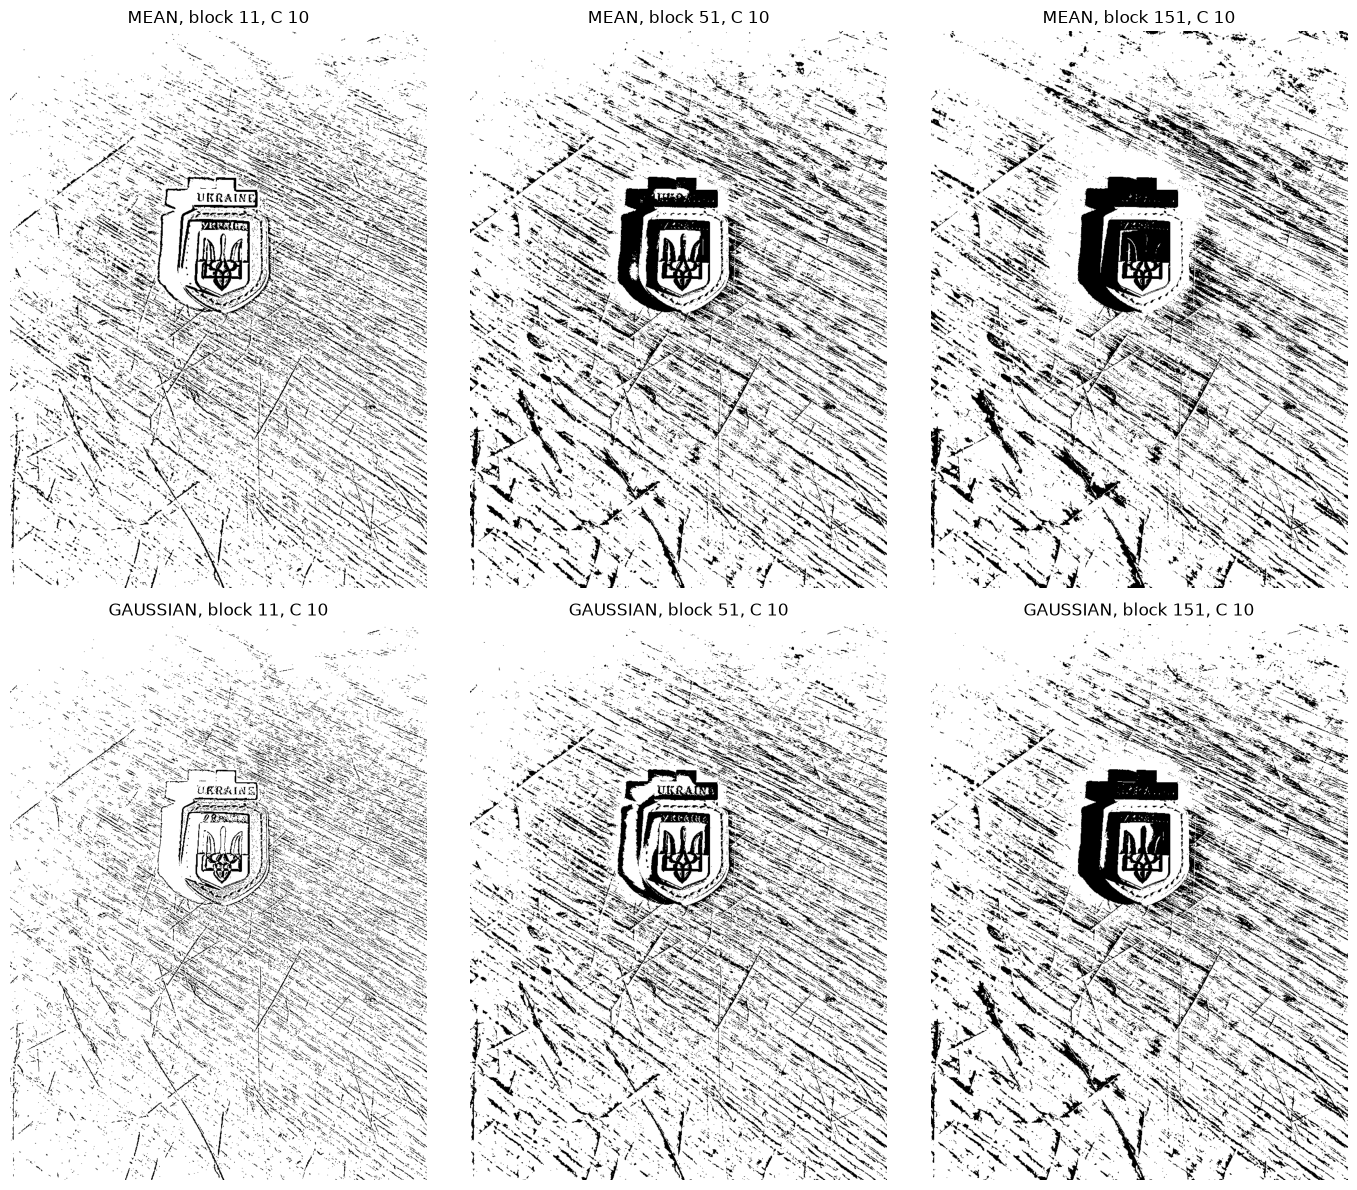


--- Execution time, ms (average of 20 runs) ---
 block     MEAN    GAUSS   ratio
    11     1.03     4.13    4.0x
    31     1.20     5.61    4.7x
    51     2.67     7.55    2.8x
   101     2.84    21.41    7.5x
   151     3.12    23.62    7.6x


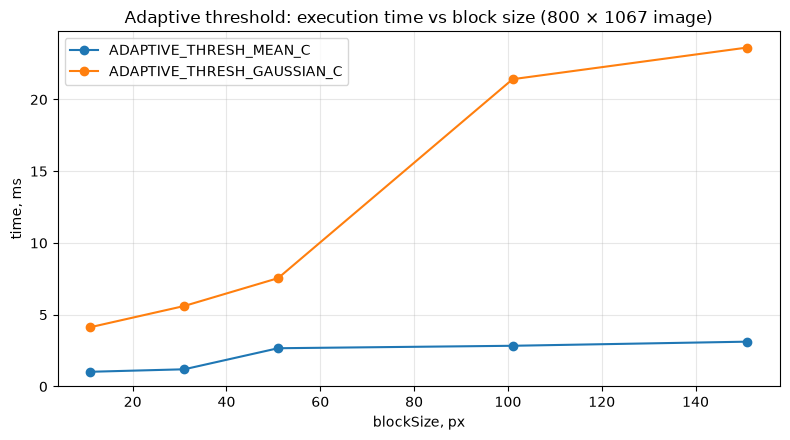

In [18]:
# Cell 6 — adaptive GAUSSIAN: main result + direct comparison with MEAN + timing
AG_BLOCK, AG_C = AM_BLOCK, AM_C                  # same parameters → fair comparison
TIME_BLOCKS = [11, 31, 51, 101, 151]             # timing experiment
N_RUNS = 20

binary_agauss = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                      cv2.THRESH_BINARY, AG_BLOCK, AG_C)
_ = cv2.imwrite(str(RESULTS_DIR / "task02_3_adaptive_gaussian.png"), binary_agauss)

# --- 1. side-by-side: MEAN vs GAUSSIAN for each block size (C fixed) ---
fig, axes = plt.subplots(2, len(BLOCKS), figsize=(14, 12))
print(f"--- MEAN vs GAUSSIAN, C = {AG_C} ---")
for j, bs in enumerate(BLOCKS):
    bm = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, bs, AG_C)
    bg = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, bs, AG_C)
    diff = 100 * np.count_nonzero(bm != bg) / bm.size            # % of pixels that differ
    lg, rg = left_right_white(bg)
    print(f"block {bs:3d} | MEAN white {white_pct(bm):5.1f}%, fragments {n_fragments(bm):4d} | "
          f"GAUSS white {white_pct(bg):5.1f}% (L {lg:4.1f} / R {rg:4.1f}), "
          f"fragments {n_fragments(bg):4d} | pixels differing {diff:4.1f}%")
    for i, (b, name) in enumerate([(bm, "MEAN"), (bg, "GAUSSIAN")]):
        axes[i, j].imshow(b, cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(f"{name}, block {bs}, C {AG_C}")
        axes[i, j].axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task02_step4_mean_vs_gaussian.png", dpi=120, bbox_inches="tight")
plt.show()

# --- 2. timing: how cost grows with blockSize ---
def time_ms(method, bs):
    cv2.adaptiveThreshold(gray, 255, method, cv2.THRESH_BINARY, bs, AG_C)       # warm-up
    t0 = time.perf_counter()
    for _ in range(N_RUNS):
        cv2.adaptiveThreshold(gray, 255, method, cv2.THRESH_BINARY, bs, AG_C)
    return (time.perf_counter() - t0) / N_RUNS * 1000

t_mean  = [time_ms(cv2.ADAPTIVE_THRESH_MEAN_C, bs) for bs in TIME_BLOCKS]
t_gauss = [time_ms(cv2.ADAPTIVE_THRESH_GAUSSIAN_C, bs) for bs in TIME_BLOCKS]

print("\n--- Execution time, ms (average of", N_RUNS, "runs) ---")
print(f"{'block':>6}{'MEAN':>9}{'GAUSS':>9}{'ratio':>8}")
timing_rows = []
for bs, tm, tg in zip(TIME_BLOCKS, t_mean, t_gauss):
    print(f"{bs:>6}{tm:>9.2f}{tg:>9.2f}{tg / tm:>7.1f}x")
    timing_rows.append([bs, round(tm, 2), round(tg, 2)])

with open(RESULTS_DIR / "task02_adaptive_timing.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["block_size", "mean_ms", "gaussian_ms"])
    w.writerows(timing_rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(TIME_BLOCKS, t_mean, marker="o", label="ADAPTIVE_THRESH_MEAN_C")
ax.plot(TIME_BLOCKS, t_gauss, marker="o", label="ADAPTIVE_THRESH_GAUSSIAN_C")
ax.set_xlabel("blockSize, px")
ax.set_ylabel("time, ms")
ax.set_title("Adaptive threshold: execution time vs block size (800 × 1067 image)")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task02_step4_timing.png", dpi=150, bbox_inches="tight")
plt.show()

# Otsu (image 4) and Otsu 

--- Otsu with / without Gaussian blur ---
no blur     | Otsu T = 115.0 | white  45.8% | L  2.7 / R 88.5 | specks  4444
blur 5x5    | Otsu T = 115.0 | white  45.9% | L  1.2 / R 89.5 | specks   605
blur 9x9    | Otsu T = 115.0 | white  45.8% | L  0.7 / R 89.8 | specks   196
blur 15x15  | Otsu T = 115.0 | white  45.5% | L  0.3 / R 90.0 | specks    70


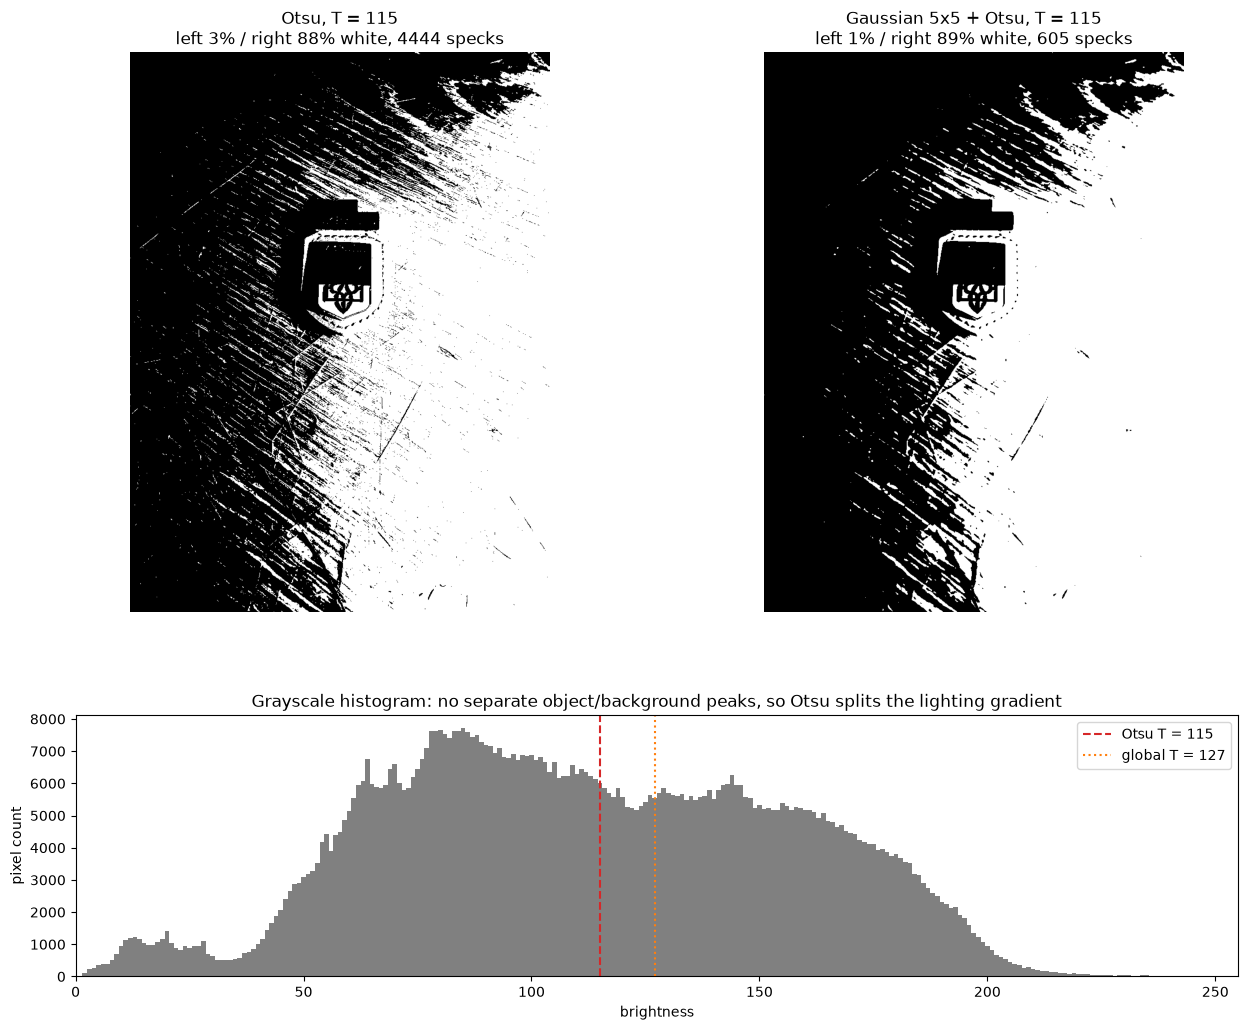

In [19]:
# Cell 7 — Otsu (image 4) and Otsu after Gaussian blur (image 5)
OTSU_BLUR = 5                               # main result for image 5
BLUR_SIZES = [0, 5, 9, 15]                  # experiment: 0 = no blur

def n_specks(b, max_area=50):
    """Tiny isolated regions (white or black, < max_area px) = salt-and-pepper noise."""
    w = cv2.connectedComponentsWithStats(b, connectivity=8)[2][1:, cv2.CC_STAT_AREA]
    k = cv2.connectedComponentsWithStats(255 - b, connectivity=8)[2][1:, cv2.CC_STAT_AREA]
    return int((w < max_area).sum() + (k < max_area).sum())

# image 4: plain Otsu (the 0 passed as thresh is ignored; Otsu computes T)
t_otsu, binary_otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_ = cv2.imwrite(str(RESULTS_DIR / "task02_4_otsu.png"), binary_otsu)

# image 5: Gaussian blur, then Otsu
gray_blur = cv2.GaussianBlur(gray, (OTSU_BLUR, OTSU_BLUR), 0)
t_otsu_blur, binary_otsu_blur = cv2.threshold(gray_blur, 0, 255,
                                              cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_ = cv2.imwrite(str(RESULTS_DIR / "task02_5_otsu_blur.png"), binary_otsu_blur)

# --- blur-size experiment ---
print("--- Otsu with / without Gaussian blur ---")
for k in BLUR_SIZES:
    src = gray if k == 0 else cv2.GaussianBlur(gray, (k, k), 0)
    t, b = cv2.threshold(src, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    left, right = left_right_white(b)
    label = "no blur" if k == 0 else f"blur {k}x{k}"
    print(f"{label:<11} | Otsu T = {t:5.1f} | white {white_pct(b):5.1f}% | "
          f"L {left:4.1f} / R {right:4.1f} | specks {n_specks(b):5d}")

# --- figure: two binary images + histogram with the chosen thresholds ---
fig = plt.figure(figsize=(15, 12))
gs = fig.add_gridspec(2, 2, height_ratios=[3, 1.4], hspace=0.25)
ax1, ax2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ax_h = fig.add_subplot(gs[1, :])

for ax, b, t, title in [(ax1, binary_otsu, t_otsu, "Otsu"),
                        (ax2, binary_otsu_blur, t_otsu_blur, f"Gaussian {OTSU_BLUR}x{OTSU_BLUR} + Otsu")]:
    left, right = left_right_white(b)
    ax.imshow(b, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{title}, T = {t:.0f}\nleft {left:.0f}% / right {right:.0f}% white, "
                 f"{n_specks(b)} specks")
    ax.axis("off")

hist = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()
ax_h.bar(np.arange(256), hist, width=1.0, color="gray")
ax_h.axvline(t_otsu, color="tab:red", linestyle="--", label=f"Otsu T = {t_otsu:.0f}")
ax_h.axvline(GLOBAL_T, color="tab:orange", linestyle=":", label=f"global T = {GLOBAL_T}")
ax_h.set_xlim(0, 255)
ax_h.set_xlabel("brightness")
ax_h.set_ylabel("pixel count")
ax_h.set_title("Grayscale histogram: no separate object/background peaks, so Otsu splits the lighting gradient")
ax_h.legend()

plt.savefig(RESULTS_DIR / "task02_step5_otsu.png", dpi=150, bbox_inches="tight")
plt.show()

# CELL 8 Comparision for All

Method              Threshold                        white%    L%    R%  |L-R|  specks  frag     ms
1 Global            127                                38.1   0.9  81.2   80.3    5058    45   0.02
2 Adaptive mean     local (block 51, C 10)             81.9  87.4  82.1    5.3    8853   426   1.13
3 Adaptive Gaussian local (block 51, C 10)             84.1  89.0  83.4    5.5    9530   428   9.41
4 Otsu              115 (auto)                         45.8   2.7  88.5   85.8    4444    23   0.76
5 Blur + Otsu       115 (auto, blur 5x5)               45.9   1.2  89.5   88.3     605    20   1.04


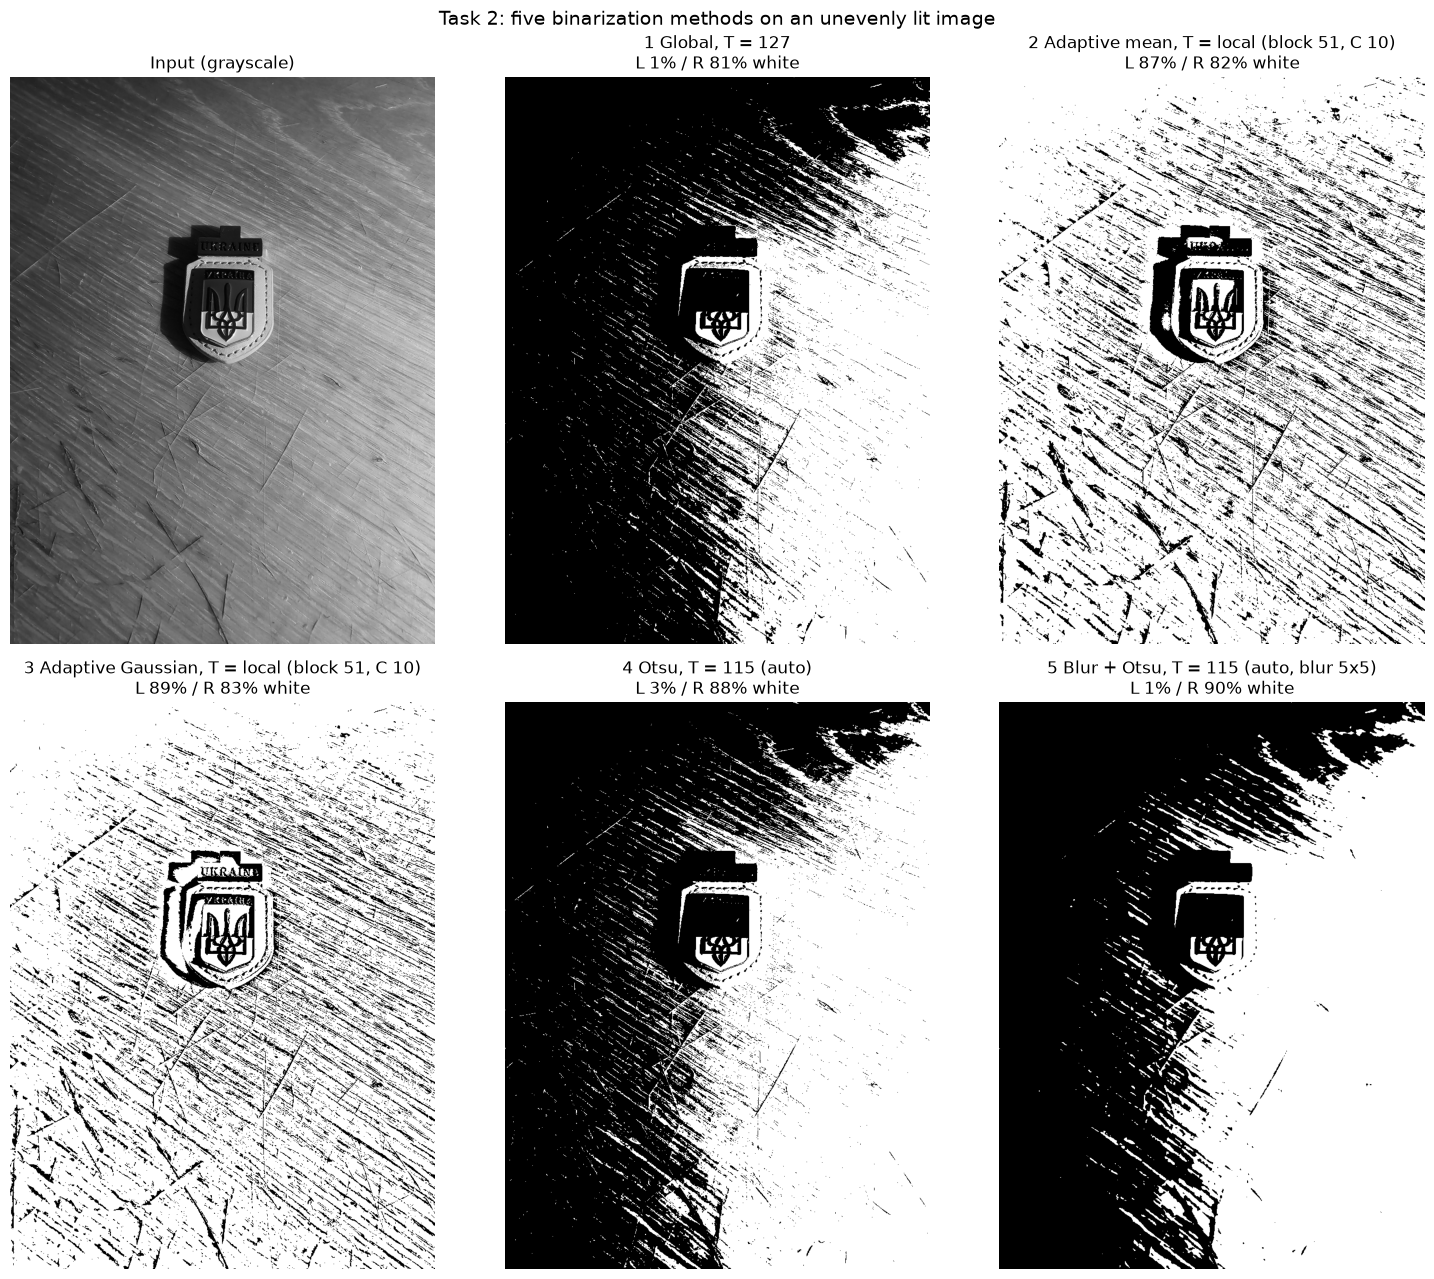

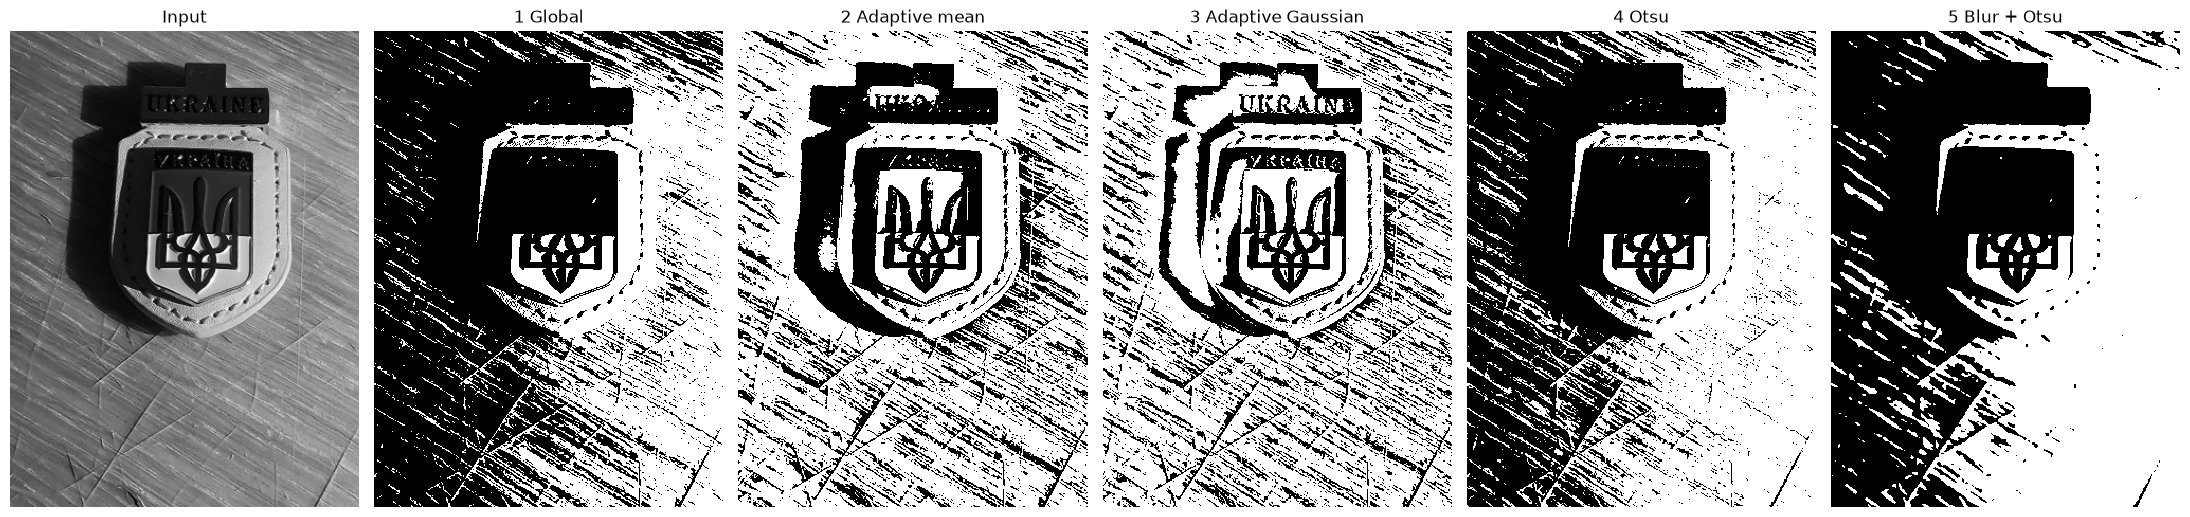

In [20]:
# Cell 8 — Step 6: comparison of all 5 binary images + summary table
CROP = (250, 700, 230, 560)        # y0, y1, x0, x1 around the badge; adjust if needed

def time_it(fn, n=20):
    fn()                                            # warm-up
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n * 1000

methods = [
    ("1 Global",            binary_global,   f"{GLOBAL_T}",
     lambda: cv2.threshold(gray, GLOBAL_T, 255, cv2.THRESH_BINARY)),
    ("2 Adaptive mean",     binary_amean,    f"local (block {AM_BLOCK}, C {AM_C})",
     lambda: cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                   cv2.THRESH_BINARY, AM_BLOCK, AM_C)),
    ("3 Adaptive Gaussian", binary_agauss,   f"local (block {AG_BLOCK}, C {AG_C})",
     lambda: cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, AG_BLOCK, AG_C)),
    ("4 Otsu",              binary_otsu,     f"{t_otsu:.0f} (auto)",
     lambda: cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)),
    ("5 Blur + Otsu",       binary_otsu_blur, f"{t_otsu_blur:.0f} (auto, blur {OTSU_BLUR}x{OTSU_BLUR})",
     lambda: cv2.threshold(cv2.GaussianBlur(gray, (OTSU_BLUR, OTSU_BLUR), 0), 0, 255,
                           cv2.THRESH_BINARY + cv2.THRESH_OTSU)),
]

# --- summary table ---
summary = []
print(f"{'Method':<20}{'Threshold':<32}{'white%':>7}{'L%':>6}{'R%':>6}{'|L-R|':>7}"
      f"{'specks':>8}{'frag':>6}{'ms':>7}")
for name, b, thr, fn in methods:
    left, right = left_right_white(b)
    row = [name, thr, round(white_pct(b), 1), round(left, 1), round(right, 1),
           round(abs(left - right), 1), n_specks(b), n_fragments(b), round(time_it(fn), 2)]
    summary.append(row)
    print(f"{row[0]:<20}{row[1]:<32}{row[2]:>7}{row[3]:>6}{row[4]:>6}{row[5]:>7}"
          f"{row[6]:>8}{row[7]:>6}{row[8]:>7}")

with open(RESULTS_DIR / "task02_summary.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["method", "threshold", "white_pct", "left_pct", "right_pct",
                "imbalance_LR", "specks_lt50px", "fragments_ge50px", "time_ms"])
    w.writerows(summary)

# --- figure 1: all 5 results + input ---
fig, axes = plt.subplots(2, 3, figsize=(15, 13))
axes = axes.ravel()
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Input (grayscale)")
for ax, (name, b, thr, _), row in zip(axes[1:], methods, summary):
    ax.imshow(b, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name}, T = {thr}\nL {row[3]:.0f}% / R {row[4]:.0f}% white")
for ax in axes:
    ax.axis("off")
plt.suptitle("Task 2: five binarization methods on an unevenly lit image", fontsize=14)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task02_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# --- figure 2: zoom on the badge ---
y0, y1, x0, x1 = CROP
fig, axes = plt.subplots(1, 6, figsize=(22, 6))
axes[0].imshow(gray[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Input")
for ax, (name, b, _, _) in zip(axes[1:], methods):
    ax.imshow(b[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(name)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task02_comparison_zoom.png", dpi=150, bbox_inches="tight")
plt.show()